In [1]:
import os

os.chdir('/Users/sebert/Documents/BulkRNAseq_Liver')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
counts=pd.read_csv('GSE135251_norm_counts_TPM_GRCh38.p13_NCBI (1).tsv',index_col=0, sep='\t')
meta=pd.read_csv('GSE135251_series_matrix (2).txt',index_col=0, sep='\t')
genes=pd.read_csv('Human.GRCh38.p13.annot (1).tsv',index_col=0, sep='\t')

/var/folders/4b/hvq_5xkd6bn_t69prnh5d_sr0000gn/T/ipykernel_31481/3440848138.py:3: DtypeWarning: Columns (8,9) have mixed types. Specify dtype option on import or set low_memory=False.
  genes=pd.read_csv('Human.GRCh38.p13.annot (1).tsv',index_col=0, sep='\t')


In [4]:
counts_with_symbol = counts.copy()
counts_with_symbol.index = counts_with_symbol.index.map(lambda gene_id: genes.loc[gene_id, 'Symbol'] if gene_id in genes.index else gene_id)

In [5]:
counts=counts_with_symbol

In [6]:
counts.head()

,GSM3998167,GSM3998168,GSM3998169,GSM3998170,GSM3998171,GSM3998172,GSM3998173,GSM3998174,GSM3998175,GSM3998176,...,GSM3998373,GSM3998374,GSM3998375,GSM3998376,GSM3998377,GSM3998378,GSM3998379,GSM3998380,GSM3998381,GSM3998382
GeneID,,,,,,,,,,,,,,,,,,,,,
DDX11L1,0.09807,0.000,0.03003,0.05406,0.07812,0.0000,0.02910,0.0301,0.000,0.03447,...,0.21540,0.3023,0.2011,0.1535,0.14880,0.15190,0.4552,0.1115,0.067,0.1092
WASH7P,5.03700,4.662,3.92600,5.45200,6.39600,3.7100,9.13000,5.1720,3.673,3.21900,...,12.53000,10.7300,9.2960,10.1100,6.11600,8.59700,8.8320,9.6160,10.170,15.9100
MIR6859-1,3.97100,4.559,2.18800,7.22300,5.69400,6.4880,8.48300,5.1190,2.172,1.67500,...,16.45000,9.1810,4.0710,4.6620,7.95500,5.90500,6.1440,7.2250,4.883,13.2700
MIR1302-2HG,0.00000,0.000,0.00000,0.08300,0.00000,0.1025,0.08935,0.0000,0.000,0.00000,...,0.09449,0.0000,0.0000,0.2357,0.09141,0.09329,0.0000,0.1141,0.000,0.1118
MIR1302-2,0.00000,0.000,0.00000,0.00000,0.00000,0.0000,0.00000,0.0000,0.000,0.00000,...,0.00000,0.0000,0.0000,0.0000,0.00000,0.00000,0.0000,0.0000,0.000,0.0000


In [7]:
counts=counts.T

In [8]:
counts.head()

GeneID,DDX11L1,WASH7P,MIR6859-1,MIR1302-2HG,MIR1302-2,FAM138A,OR4F5,LOC100996442,LOC729737,DDX11L17,...,ND4,TRNH,TRNS2,TRNL2,ND5,ND6,TRNE,CYTB,TRNT,TRNP
GSM3998167,0.09807,5.037,3.971,0.000,0.0,0.00000,0.0,0.2428,0.36500,0.13440,...,23560.0,40.70,50.34,41.07,3623.0,5817.0,5436.0,15830.0,202.1,2272.0
GSM3998168,0.00000,4.662,4.559,0.000,0.0,0.00000,0.0,0.2661,0.29450,0.00000,...,24760.0,23.36,34.68,32.31,4177.0,6530.0,5303.0,14390.0,152.2,1763.0
GSM3998169,0.03003,3.926,2.188,0.000,0.0,0.00000,0.0,0.1520,0.09968,0.03087,...,24220.0,56.08,73.99,62.88,4577.0,5861.0,4650.0,14400.0,290.1,2133.0
GSM3998170,0.05406,5.452,7.223,0.083,0.0,0.03952,0.0,0.2007,0.19580,0.02779,...,18620.0,44.01,53.73,39.62,3612.0,5331.0,4517.0,13590.0,159.7,1688.0
GSM3998171,0.07812,6.396,5.694,0.000,0.0,0.00000,0.0,0.2197,0.29080,0.10710,...,27360.0,82.92,112.30,98.15,6753.0,8972.0,6753.0,17100.0,221.6,1868.0


In [9]:
meta_with_group = meta.T.copy()
meta_with_group['Group'] = meta.loc['Group']
meta_with_group.head()

!Sample_geo_accession,!Sample_source_name_ch1,!Sample_organism_ch1,!Sample_characteristics_ch1,!Sample_characteristics_ch1,Group,!Sample_characteristics_ch1,!Sample_characteristics_ch1,!Sample_title
GSM3998167,NAFLD_early_liver biopsy,Homo sapiens,nas score: 4,fibrosis stage: 2,NASH_F2,disease: NAFLD,Stage: early,Liver patient 97
GSM3998168,NAFLD_moderate_liver biopsy,Homo sapiens,nas score: 7,fibrosis stage: 3,NASH_F3,disease: NAFLD,Stage: moderate,Liver patient 98
GSM3998169,NAFLD_early_liver biopsy,Homo sapiens,nas score: 7,fibrosis stage: 2,NASH_F2,disease: NAFLD,Stage: early,Liver patient 101
GSM3998170,NAFLD_moderate_liver biopsy,Homo sapiens,nas score: 6,fibrosis stage: 3,NASH_F3,disease: NAFLD,Stage: moderate,Liver patient 102
GSM3998171,NAFLD_early_liver biopsy,Homo sapiens,nas score: 5,fibrosis stage: 0,NASH_F0-F1,disease: NAFLD,Stage: early,Liver patient 105


In [10]:
merged_df = meta_with_group.merge(counts, left_index=True, right_index=True)

In [11]:
merged_df.head()

,!Sample_source_name_ch1,!Sample_organism_ch1,!Sample_characteristics_ch1,!Sample_characteristics_ch1,Group,!Sample_characteristics_ch1,!Sample_characteristics_ch1,!Sample_title,DDX11L1,WASH7P,...,ND4,TRNH,TRNS2,TRNL2,ND5,ND6,TRNE,CYTB,TRNT,TRNP
GSM3998167,NAFLD_early_liver biopsy,Homo sapiens,nas score: 4,fibrosis stage: 2,NASH_F2,disease: NAFLD,Stage: early,Liver patient 97,0.09807,5.037,...,23560.0,40.70,50.34,41.07,3623.0,5817.0,5436.0,15830.0,202.1,2272.0
GSM3998168,NAFLD_moderate_liver biopsy,Homo sapiens,nas score: 7,fibrosis stage: 3,NASH_F3,disease: NAFLD,Stage: moderate,Liver patient 98,0.00000,4.662,...,24760.0,23.36,34.68,32.31,4177.0,6530.0,5303.0,14390.0,152.2,1763.0
GSM3998169,NAFLD_early_liver biopsy,Homo sapiens,nas score: 7,fibrosis stage: 2,NASH_F2,disease: NAFLD,Stage: early,Liver patient 101,0.03003,3.926,...,24220.0,56.08,73.99,62.88,4577.0,5861.0,4650.0,14400.0,290.1,2133.0
GSM3998170,NAFLD_moderate_liver biopsy,Homo sapiens,nas score: 6,fibrosis stage: 3,NASH_F3,disease: NAFLD,Stage: moderate,Liver patient 102,0.05406,5.452,...,18620.0,44.01,53.73,39.62,3612.0,5331.0,4517.0,13590.0,159.7,1688.0
GSM3998171,NAFLD_early_liver biopsy,Homo sapiens,nas score: 5,fibrosis stage: 0,NASH_F0-F1,disease: NAFLD,Stage: early,Liver patient 105,0.07812,6.396,...,27360.0,82.92,112.30,98.15,6753.0,8972.0,6753.0,17100.0,221.6,1868.0


In [12]:
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 20
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

In [13]:
from matplotlib.pyplot import rc_context

In [14]:
merged_df = merged_df[merged_df['Group'] != 'control']

In [15]:

from matplotlib import cm

# Generate 4 shades of magenta (light → intense) using "PuRd" colormap
magentas = [cm.PuRd(i) for i in np.linspace(0.3, 0.9, 5)]

# Add gray as the first color
custom_palette = magentas  # total = 5 colors

/var/folders/4b/hvq_5xkd6bn_t69prnh5d_sr0000gn/T/ipykernel_31481/2480441715.py:26: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/var/folders/4b/hvq_5xkd6bn_t69prnh5d_sr0000gn/T/ipykernel_31481/2480441715.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontstyle='italic')
/var/folders/4b/hvq_5xkd6bn_t69prnh5d_sr0000gn/T/ipykernel_31481/2480441715.py:50: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


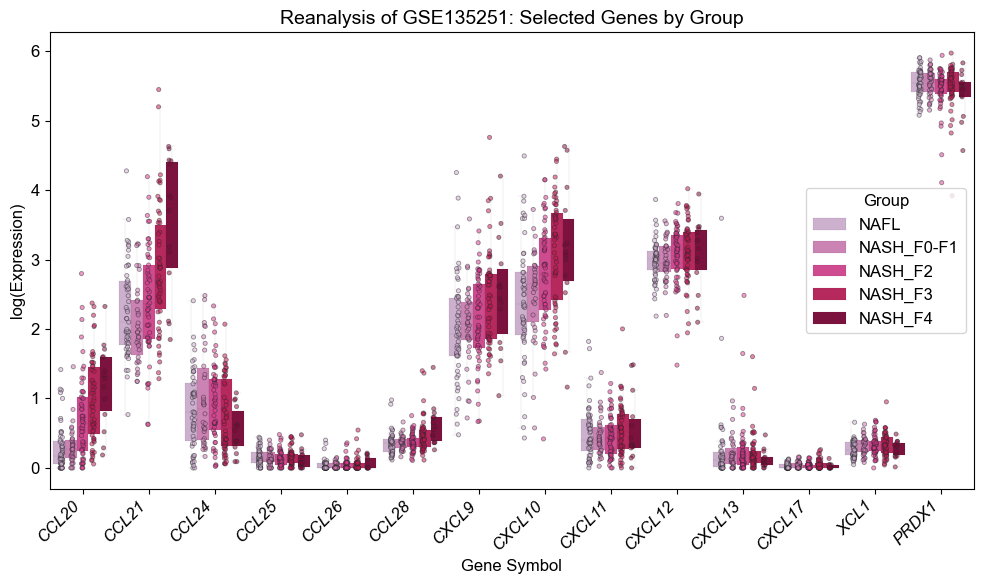

In [16]:
genes_of_interest = ['CCL2', 'CCL20', 'MIF','DDT', 'CCR2', 'CCR4', 'CCR6', 'CXCR4', "CD74" ]
genes_of_interest = ["CCL20", "CCL21", "CCL24", "CCL25", "CCL26", "CCL28", "CXCL9", "CXCL10", "CXCL11", "CXCL12", "CXCL13", "CXCL17", "XCL1", "PRDX1"
]
#genes_of_interest = ["CCL20",  "CCL24", "CCL25", "CCL26", "CCL28", "CXCL9", "CXCL10", "CXCL11", "CXCL12", "CXCL13", "CXCL17"]
                     
group_order = ["NAFL", "NASH_F0-F1", "NASH_F2", "NASH_F3", "NASH_F4"] 
# Filter for genes that exist in the dataframe
available_genes = [gene for gene in genes_of_interest if gene in merged_df.columns]

# Melt the dataframe for plotting
plot_df = merged_df.melt(id_vars=['Group'], value_vars=available_genes, var_name='Gene', value_name='Expression')
plot_df = plot_df.sort_values(by='Group', ascending=True)
with rc_context({"figure.figsize": (10, 6), "font.size": 12}):
    ax = sns.boxplot(
        data=plot_df,
        x="Gene",
        y=np.log1p(plot_df["Expression"]),
        hue="Group",
        palette=custom_palette,
        order=genes_of_interest,     # order of genes on x-axis
        hue_order=group_order,        # order of groups in bars/legend
        width=0.9,
        linewidth=0.05,
        showfliers=False,  # hide outliers
    )
    sns.stripplot(
        data=plot_df,
        x="Gene",
        y=np.log1p(plot_df["Expression"]),
        hue="Group",
        order=genes_of_interest,
        hue_order=plot_df["Group"].unique(),
        dodge=True,
        alpha=0.5,              # solid dots
        size=3,               # dot size
        jitter=True,
        marker="o",
        edgecolor="gray",     # border color
        linewidth=0.6,
        palette=custom_palette,
        facecolor="white",    # inside white
        ax=ax
    )

    ax.set_title("Reanalysis of GSE135251: Selected Genes by Group", fontsize=14)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontstyle='italic')
    ax.set_ylabel("log(Expression)")
    ax.set_xlabel("Gene Symbol")
    ax.set_title("Reanalysis of GSE135251: Selected Genes by Group", fontsize=14)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_ylabel("log(Expression)")
    ax.set_xlabel("Gene Symbol")

    # Remove duplicate legends (boxplot + stripplot)
    handles, labels = ax.get_legend_handles_labels()
    n_groups = len(plot_df["Group"].unique())
    ax.legend(handles[:n_groups], labels[:n_groups], title="Group")


    plt.tight_layout()
    plt.savefig(
        "GSE135251_Genes_of_Interest_Boxplot_SE.pdf",
        bbox_inches="tight",
        transparent=True
    )


In [17]:
plot_df['raw_Expression'] = (plot_df['Expression'])
plot_df['Expression'] = np.log1p(plot_df['Expression'])
plot_df.head()

,Group,Gene,Expression,raw_Expression
1436,NAFL,CXCL9,2.879198,16.80000
540,NAFL,CCL24,0.140544,0.15090
541,NAFL,CCL24,0.085214,0.08895
542,NAFL,CCL24,0.541335,0.71830
1265,NAFL,CXCL9,2.008617,6.45300


/var/folders/4b/hvq_5xkd6bn_t69prnh5d_sr0000gn/T/ipykernel_31481/2509651482.py:38: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

CCL21_NASH_F0-F1 vs. CCL21_NASH_F3: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.435e-03 U_stat=4.220e+02
CCL20_NAFL vs. CCL20_NASH_F2: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:4.010e-03 U_stat=7.160e+02
CCL20_NASH_F0-F1 vs. CCL20_NASH_F3: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:8.871e-06 U_stat=2.910e+02
CCL20_NAFL vs. CCL20_NASH_F3: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:6.751e-08 U_stat=4.115e+02
CCL21_NAFL vs. CCL21_NASH_F3: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:4.496e-02 U_stat=8.245e+02
CCL20_NASH_F0-F1 vs. CCL20_NASH_F4: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.923e-03 U_stat=4.800e+01
CCL21_NASH_F0-F1 vs. C

/var/folders/4b/hvq_5xkd6bn_t69prnh5d_sr0000gn/T/ipykernel_31481/2509651482.py:87: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontstyle='italic', fontsize=12)


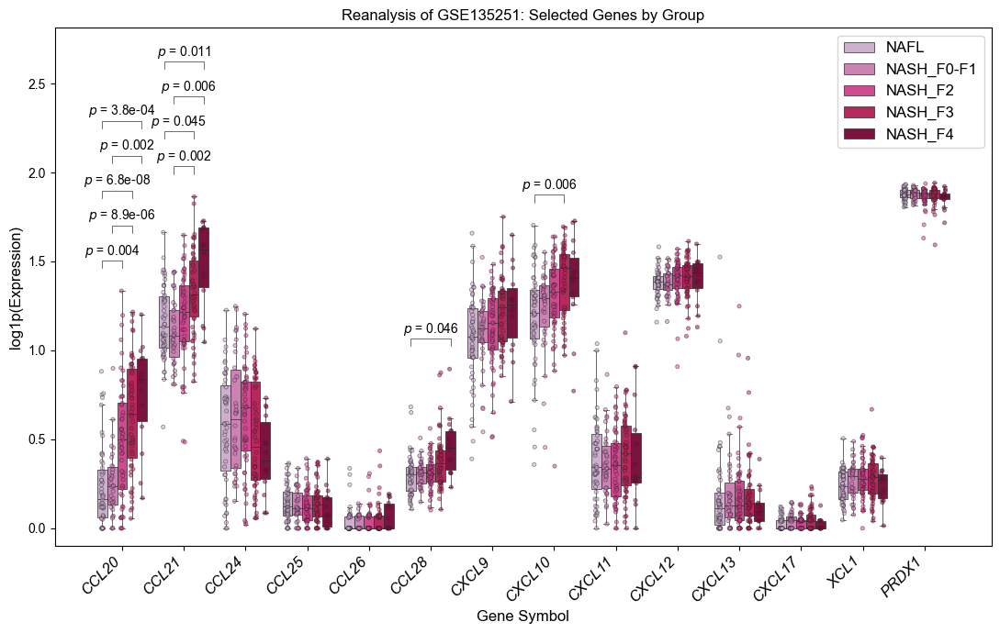

In [18]:
from statannotations.Annotator import Annotator
from statannotations.Annotator import PValueFormat

# Define your comparisons (pairwise group comparisons for each gene)
# Example: compare all groups within each gene
# Only compare "NAFL" vs. each other group, for each gene
class MyPvalueFormat(PValueFormat):
    def format_data(self, result):
        width = ".3f" if result.pvalue >= 0.001 else ".1e"
        return f"$p$ = {result.pvalue:{width}}{result.significance_suffix}"
controls = ["NAFL", "NASH_F0-F1"]

seen = set()
comparisons = []
for control in controls:
    for gene in genes_of_interest:
        for group in group_order:
            if group != control:
                comp = ((gene, control), (gene, group))
                if comp not in seen:
                    comparisons.append(comp)
                    seen.add(comp)


with rc_context({"figure.figsize": (11, 7), "font.size": 10}):
    ax = sns.boxplot(
        data=plot_df,
        x="Gene",
        y=np.log1p(plot_df["Expression"]),
        hue="Group",
        palette=custom_palette,
        order=genes_of_interest,
        hue_order=group_order,
        #width=0.9,
        linewidth=0.5,
        showfliers=False,
    )
    sns.stripplot(
        data=plot_df,
        x="Gene",
        y=np.log1p(plot_df["Expression"]),
        hue="Group",
        order=genes_of_interest,
        hue_order=group_order,
        dodge=True,
        alpha=0.5,
        size=3,
        jitter=True,
        marker="o",
        edgecolor="gray",
        linewidth=0.6,
        palette=custom_palette,
        facecolor="white",
        ax=ax
    )

    # Add statistics with statannotations
    annotator = Annotator(
        ax,
        pairs=comparisons,
        data=plot_df,
        x="Gene",
        y=(plot_df["Expression"]),
        hue="Group",
        order=genes_of_interest,
        hue_order=group_order
    )

    annotator.configure(
        test='Mann-Whitney',  # or 't-test_ind', 'Kruskal', etc.
        text_format='full',   # 'star' or 'simple' (p-value)
        loc='inside',         # position of annotation
        verbose=2,
        hide_non_significant=True,  # Hide non-significant comparisons
        show_test_name=False,
        comparisons_correction='bonf',  # Multiple testing correction
        pvalue_format_string='{:.1e}',
        fontsize=12,
        line_width=0.5,
        line_offset=5
    
    )
    annotator._pvalue_format = MyPvalueFormat()
    annotator.apply_and_annotate()

    ax.set_title("Reanalysis of GSE135251: Selected Genes by Group", fontsize=12)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontstyle='italic', fontsize=12)
    ax.set_ylabel("log1p(Expression)", fontsize=12)
    ax.set_xlabel("Gene Symbol", fontsize=12)
   

    # Remove duplicate legends (boxplot + stripplot)
    handles, labels = ax.get_legend_handles_labels()
    n_groups = len(plot_df["Group"].unique())
    ax.legend(handles[:n_groups], labels[:n_groups], title=None, fontsize=12, bbox_to_anchor=(1,1))
   

    plt.tight_layout()
    plt.savefig(
        "GSE135251_Genes_of_Interest_Boxplot_SE_withStats_multi.pdf",
        bbox_inches="tight",
        transparent=True
    )
    plt.show()
